# 합성곱 신경망의 시각화

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/8-3.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

In [1]:
import matplotlib.pyplot as plt

import tensorflow as tf
import keras

keras.utils.set_random_seed(42)

## 가중치 시각화

In [2]:
best_cnn_model_path = './best-cnn-model.keras'
model = keras.models.load_model(best_cnn_model_path)
model.layers

[<Conv2D name=conv2d, built=True>,
 <MaxPooling2D name=max_pooling2d, built=True>,
 <Conv2D name=conv2d_1, built=True>,
 <MaxPooling2D name=max_pooling2d_1, built=True>,
 <Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dropout name=dropout, built=True>,
 <Dense name=dense_1, built=True>]

In [4]:
conv = model.layers[0]
print(conv.weights[0].shape, conv.weights[1].shape)

conv_weights = conv.weights[0].numpy()
print(conv_weights.mean(), conv_weights.std())

(3, 3, 1, 32) (32,)
-0.014085422 0.2481788


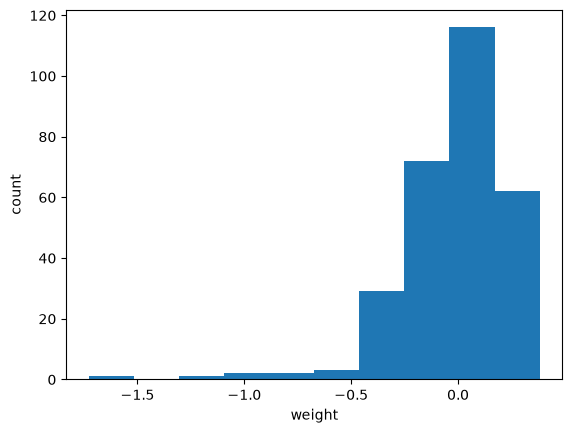

In [5]:
plt.hist(conv_weights.reshape(-1,1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

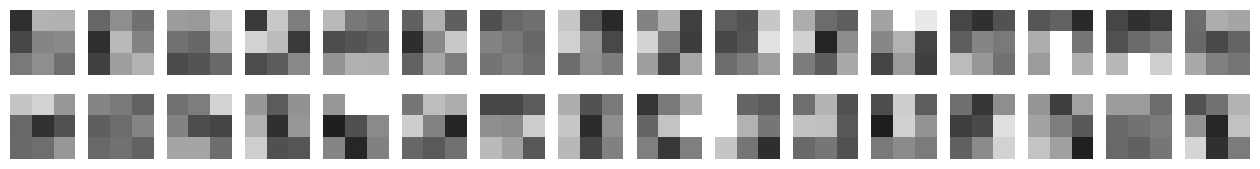

In [6]:
fig, axes = plt.subplots(2, 16, figsize=(16, 2))
for i in range(2):
    for j in range(16):
        axes[i,j].imshow(conv_weights[:,:,0,i*16+j], vmin=-0.5, vmax=0.5, cmap='gray_r')
        axes[i,j].axis('off')
plt.show()

In [8]:
no_training_model = keras.Sequential()
no_training_model.add(keras.layers.Input(shape=(28,28,1)))
no_training_model.add(keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu', padding='same'))
no_training_model.layers

[<Conv2D name=conv2d_1, built=True>]

In [9]:
no_training_conv = no_training_model.layers[0]
print(no_training_conv.weights[0].shape)

no_training_weights = no_training_conv.weights[0].numpy()
print(no_training_weights.mean(), no_training_weights.std())

(3, 3, 1, 32)
-0.0009919289 0.085228495


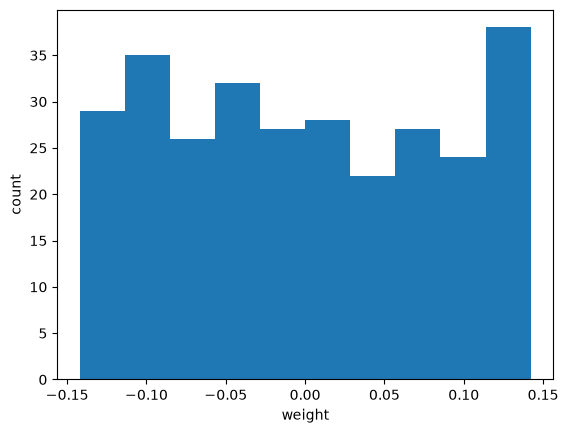

In [10]:
plt.hist(no_training_weights.reshape(-1,1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

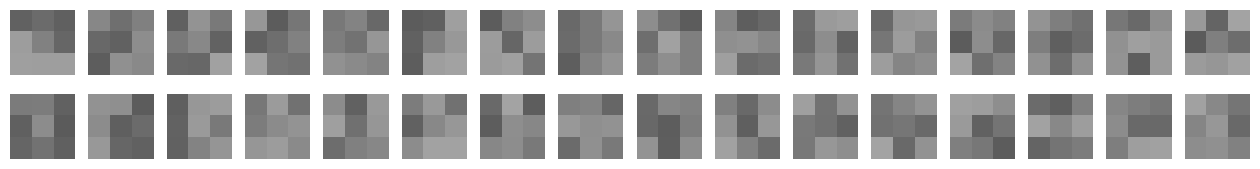

In [11]:
fig, axes = plt.subplots(2, 16, figsize=(16, 2))
for i in range(2):
    for j in range(16):
        axes[i,j].imshow(no_training_weights[:,:,0,i*16+j], vmin=-0.5, vmax=0.5, cmap='gray_r')
        axes[i,j].axis('off')
plt.show()

## 함수형 API

In [18]:
print(model.inputs)
conv_acti = keras.Model(model.inputs, model.layers[0].output)
print(conv_acti)

[<KerasTensor shape=(None, 28, 28, 1), dtype=float32, sparse=False, ragged=False, name=input_layer>]
<Functional name=functional_12, built=True>


## 특성 맵 시각화

In [19]:
(train_input, train_target), (test_input, test_target) = keras.datasets.fashion_mnist.load_data()
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


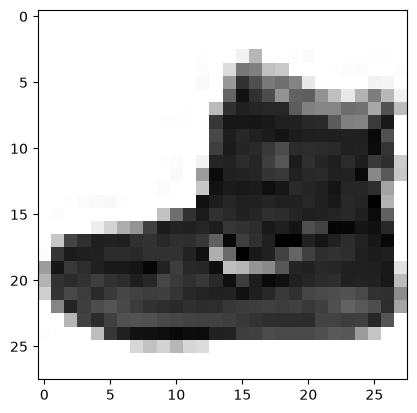

In [20]:
plt.imshow(train_input[0], cmap='gray_r')
plt.show()

In [27]:
print(train_input[0:1].shape)
inputs = train_input[0:1].reshape(-1, 28, 28, 1)/255.0
print(inputs.shape)

feature_maps = conv_acti.predict(inputs)
print(feature_maps.shape)

(1, 28, 28)
(1, 28, 28, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
(1, 28, 28, 32)


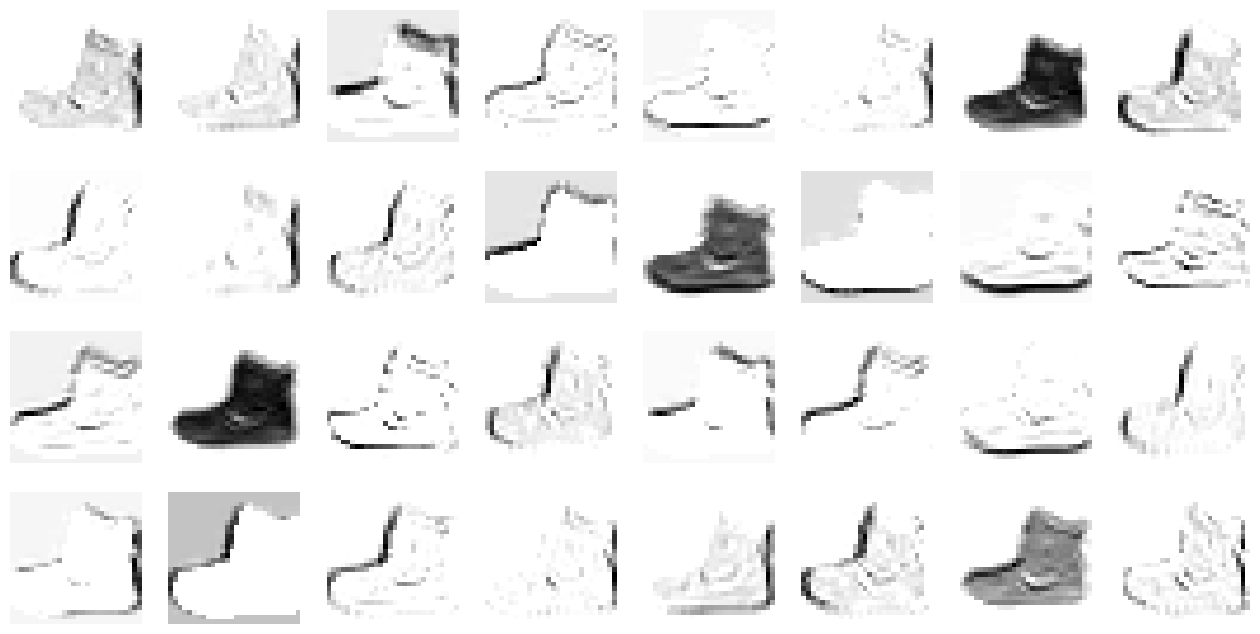

In [30]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i in range(4):
    for j in range(8):
        axes[i,j].imshow(feature_maps[0,:,:,i*8+j], cmap='gray_r')
        axes[i,j].axis('off')
plt.show()

In [34]:
# print(model.inputs)
# conv_acti = keras.Model(model.inputs, model.layers[0].output)
# print(conv_acti)

conv2_acti = keras.Model(model.inputs, model.layers[2].output)
print(conv2_acti)

inputs = train_input[0:1].reshape(-1, 28, 28, 1)/255.0
feature_maps = conv2_acti.predict(inputs)
print(feature_maps.shape)

<Functional name=functional_16, built=True>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
(1, 14, 14, 64)


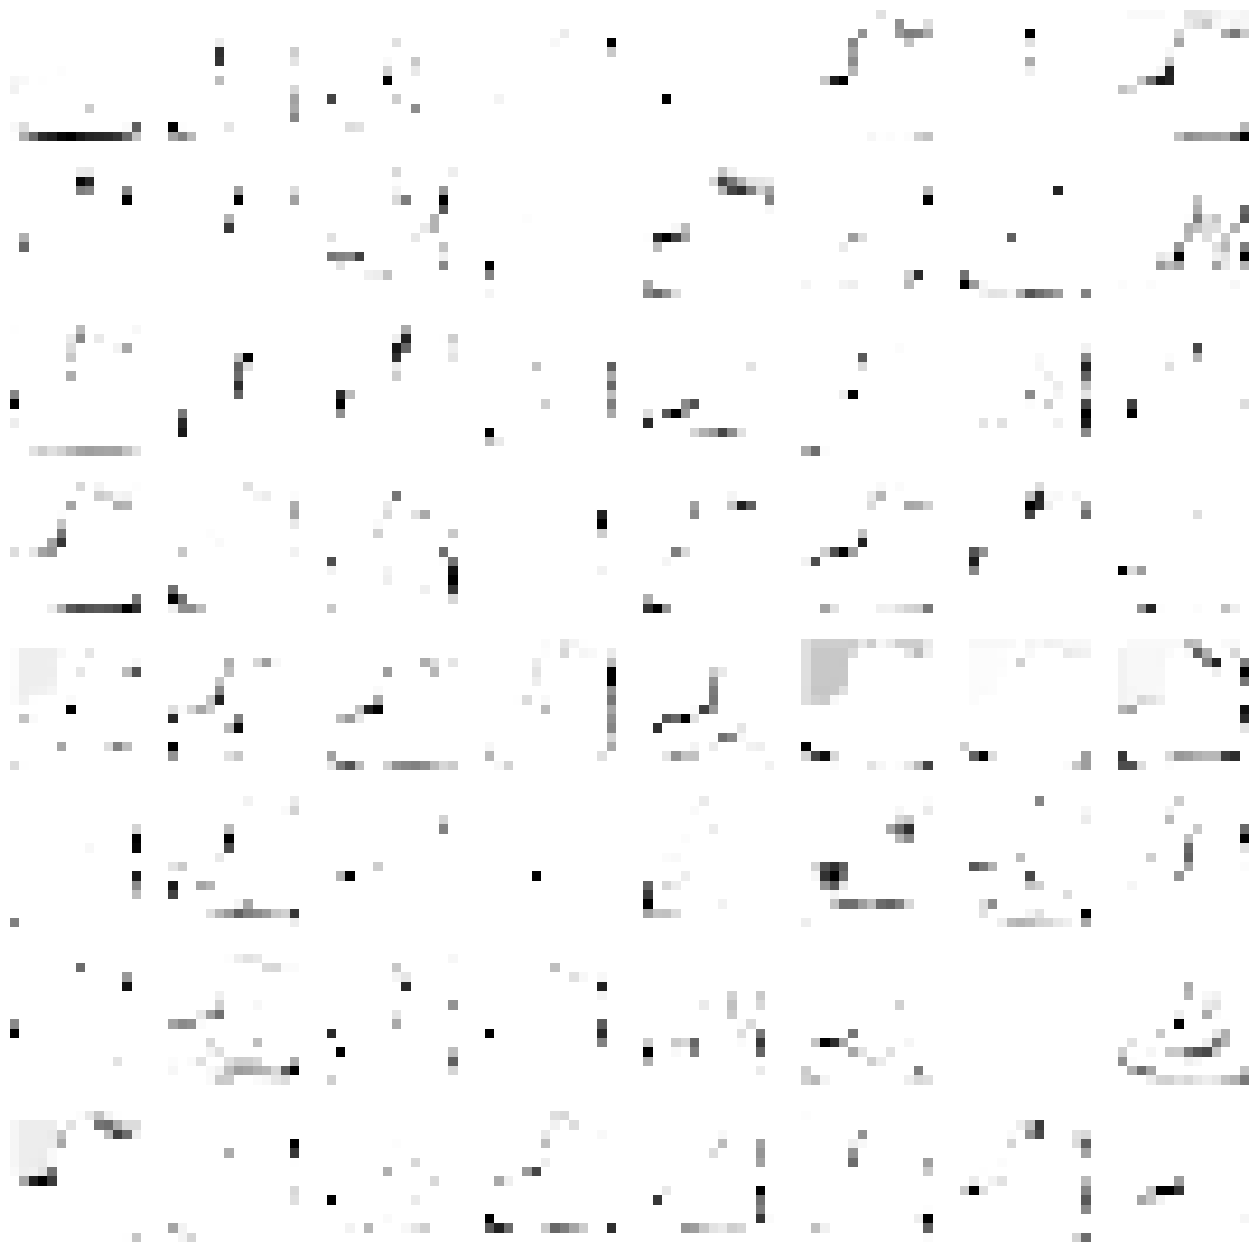

In [35]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))
for i in range(8):
    for j in range(8):
        axes[i,j].imshow(feature_maps[0,:,:,i*8+j], cmap='gray_r')
        axes[i,j].axis('off')
plt.show()